# 11 · Why a graph: the loop as state, nodes, edges and saved steps
Level L2 · Part 2 · core · ~30 min · builds on 05, 09

## Goal
Run the same agent twice: once as the loop from lesson 05, and once as a graph. Make the lookup fail halfway through. The loop loses its
place: its messages go with the function, so a retry would start over and pay the model again. The graph saved each step, so it resumes
where it stopped and makes only the model call it still needs. Then read the saved steps and draw them.

## Why it matters
A loop keeps its state in local variables. When the process stops, the state goes with it: the messages, the step count, and the
money spent. A timeout in a tool then costs the whole run again. A customer who waited for an answer gets a second bill and a second wait.

| A loop | A graph with a checkpointer |
|---|---|
| State lives in variables; a crash loses it | State is saved after each step, under a thread id |
| Resume means starting again | Resume means continuing from the last saved step |
| The history is what you printed | The history is saved; you can read or replay any step |

**What it makes easy:** a run you can stop, inspect and continue. **When you don't need it:** a run that takes a second and cannot fail
halfway.

## The idea
A **graph** names each step as a node and writes the state after each node. A **checkpointer** saves that state under a **thread id**. A
run is a path through the graph; a checkpoint is a snapshot of one step on that path. When a run stops, the checkpoints remain, and a new
run with the same thread id continues from the last one.

## Picture
The same agent, with the saved steps as the path. Each checkpoint is one node's output. `show_mermaid` is a course helper (in
`graph_view.py`) that draws a flowchart written as text.

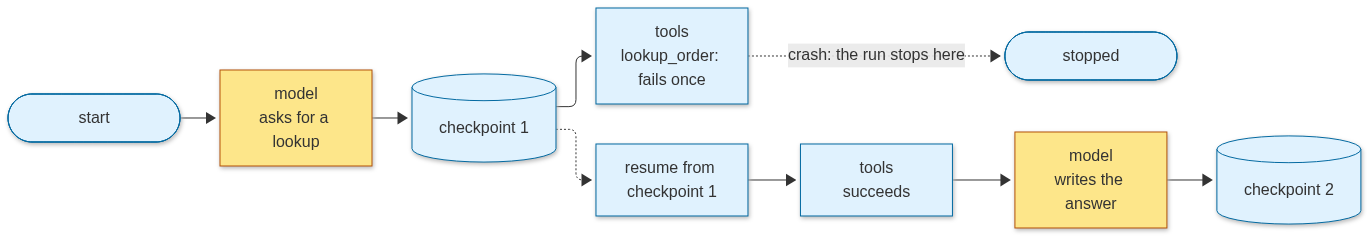

In [1]:
import sys; sys.path.insert(0, "../../..")  # the topic folder: llm_setup.py, graph_view.py and tut_env.py live there

from graph_view import show_mermaid

show_mermaid("""
flowchart LR
  S(["start"]) --> M1["model<br/>asks for a lookup"]
  M1 --> C1[("checkpoint 1")]
  C1 --> T["tools<br/>lookup_order: fails once"]
  T -. "crash: the run stops here" .-> X(["stopped"])
  C1 -.-> R["resume from checkpoint 1"]
  R --> T2["tools<br/>succeeds"]
  T2 --> M2["model<br/>writes the answer"]
  M2 --> C2[("checkpoint 2")]
  classDef model fill:#fde68a,stroke:#b45309
  classDef code fill:#e0f2fe,stroke:#0369a1
  class M1,M2 model
  class S,C1,T,X,R,T2,C2 code
""")

## Step by step
**Step 1 · setup (one model for the lesson).** The key is read from `.env`, never typed here. Three course helpers are used from here on,
not LangGraph itself: `llm_replay` saves each model answer the first time, so later runs replay it with no key; `get_llm()` returns the
course model; `show_graph` draws a compiled graph. The data is `data/support_eval.json`, a made-up order list for a fictional support
desk (Brightside Outfitters). It is course example data, not a licensed dataset.

In [2]:
import llm_replay  # course helper: records and replays model calls (not part of LangGraph)
llm_replay.start("11_why-a-graph")

import json
from pathlib import Path
from langchain_core.messages import HumanMessage, ToolMessage
from langchain_core.tools import tool
from langgraph.checkpoint.memory import InMemorySaver
from langgraph.graph import END, START, MessagesState, StateGraph
from langgraph.prebuilt import ToolNode, tools_condition
from pydantic import BaseModel, ConfigDict, Field
from llm_setup import get_llm  # course helper: the shared model setup (the course model)
from graph_view import show_graph  # course helper: draws a compiled graph

llm = get_llm()
DATA = json.loads((Path("../../../data") / "support_eval.json").read_text())
ORDERS = DATA["world"]["orders"]
print("peek at the data, order 1003:", ORDERS["1003"])
FAILURES = {"left": 1}  # the first lookup times out; the next one works
LOOKUPS = []  # every call that reached the lookup
MODEL_CALLS = []  # one entry per model call this lesson makes

LLM mode: replay (11_why-a-graph.yaml)


Gemini on Vertex AI · API key loaded: True
peek at the data, order 1003: {'status': 'lost', 'days_late': 9, 'total': 89.5}


**The lookup tool.** `lookup_order` is the one tool. It is a Python function the model may ask for, and it raises `TimeoutError` the
first time, to simulate a slow order service. `ask` (also defined here) is the single door to the model: it counts each call, so the
numbers below are the same whether the answers are recorded or replayed.

In [3]:
class OrderQuery(BaseModel):
    model_config = ConfigDict(extra="forbid")
    order_id: str = Field(description="The order number the customer wrote: four digits, such as 1003.", pattern=r"^\d{4}$")


@tool(args_schema=OrderQuery)
def lookup_order(order_id: str) -> dict:
    """Look up one customer order: its status and days late. Use it when the customer gives an order number."""
    LOOKUPS.append(order_id)
    if FAILURES["left"] > 0:
        FAILURES["left"] -= 1
        raise TimeoutError("the order service did not answer in time")
    return ORDERS.get(order_id, {"error": f"no order {order_id}"})


model = llm.bind_tools([lookup_order])


def ask(messages: list):
    MODEL_CALLS.append(len(messages))  # count the call, then make it
    return model.invoke(messages)  # a paid model call (recorded once, replayed after)

**Step 2 · the loop (the lesson 05 loop, without caps, so the failure is visible).** The state is `messages`, a local variable. The tool
raises, the exception leaves the loop, and its messages go with the function.

In [4]:
def loop(question: str):
    messages = [HumanMessage(content=question)]
    while True:
        reply = ask(messages)
        if not reply.tool_calls:
            return reply.text
        messages.append(reply)
        for c in reply.tool_calls:
            result = lookup_order.invoke(c["args"])  # raises on the first call: the loop has no saved state to return to
            messages.append(ToolMessage(content=json.dumps(result), tool_call_id=c["id"]))


calls_before = len(MODEL_CALLS)
try:
    loop("Order 1003 never arrived. What is its status?")
except TimeoutError as error:
    print("loop stopped:", error, "· its messages are gone with the function")
print("model calls so far:", len(MODEL_CALLS) - calls_before)

loop stopped: the order service did not answer in time · its messages are gone with the function
model calls so far: 1


**Step 3 · the same agent as a graph (one failed tool call, then a saved run).** The model node and the tool node are separate. Every
node's output is saved under the thread id, so the failure is one step, not the whole run.

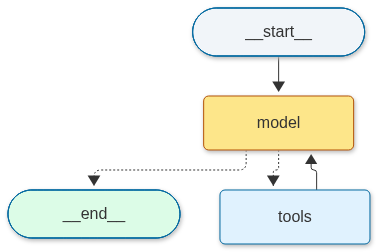

graph stopped: the order service did not answer in time
saved steps so far: 3 · model calls so far: 1


In [5]:
def call_model(state: MessagesState) -> dict:
    return {"messages": [ask(state["messages"])]}


g = StateGraph(MessagesState)
g.add_node("model", call_model)
g.add_node("tools", ToolNode([lookup_order]))
g.add_edge(START, "model")
g.add_conditional_edges("model", tools_condition, {"tools": "tools", END: END})
g.add_edge("tools", "model")
desk = g.compile(checkpointer=InMemorySaver())
show_graph(desk, model_nodes=("model",))

FAILURES["left"] = 1  # the timeout happens again on this run
LOOKUPS.clear()  # count this run's lookups only
CFG = {"configurable": {"thread_id": "order-1003"}}  # one thread id = one saved run
before = len(MODEL_CALLS)
try:
    desk.invoke({"messages": [HumanMessage(content="Order 1003 never arrived. What is its status?")]}, CFG)
except TimeoutError as error:
    print("graph stopped:", error)
print("saved steps so far:", len(list(desk.get_state_history(CFG))), "· model calls so far:", len(MODEL_CALLS) - before)

**Step 4 · resume from the checkpoint.** Passing `None` as the input resumes the thread from its last saved step. The model call that
already ran (the lookup request) is not made again. The resume makes one model call, for the answer after the tool result, and the tool
node is retried and succeeds.

In [6]:
resume_before = len(MODEL_CALLS)
final = desk.invoke(None, CFG)
print("answer:", final["messages"][-1].text)
print("lookups attempted:", LOOKUPS, "· model calls on resume:", len(MODEL_CALLS) - resume_before)
llm_replay.stop()  # the last model call of this lesson

answer: I'm very sorry to hear that. I've checked the status of order 1003, and it appears to be marked as lost. It is currently 9 days past its expected delivery date.

I apologize for this inconvenience. Would you like me to help you initiate a refund or look into a replacement for this order?
lookups attempted: ['1003', '1003'] · model calls on resume: 1


## Read the saved steps
Every checkpoint is a record: which step ran, and the state after it. The slider below moves through them. A checkpoint is what makes a
resume possible, and what a reviewer reads when a run went wrong.

In [7]:
import ipywidgets as widgets

history = list(reversed(list(desk.get_state_history(CFG))))  # oldest first


def show_step(i: int) -> None:
    snap = history[i]
    ran = [n for n in history[i - 1].next if not n.startswith("__")] if i else ["the empty start"]
    msgs = snap.values.get("messages", [])
    print(f"checkpoint {i} · after {', '.join(ran) or 'the input'} · next: {', '.join(snap.next) or 'done'} · "
          f"{len(msgs)} messages · last: {type(msgs[-1]).__name__ if msgs else '-'}")


for i in range(len(history)):
    show_step(i)
_ = widgets.interact(show_step, i=widgets.IntSlider(min=0, max=len(history) - 1, value=len(history) - 1, description="checkpoint"))

checkpoint 0 · after the empty start · next: __start__ · 0 messages · last: -
checkpoint 1 · after the input · next: model · 1 messages · last: HumanMessage
checkpoint 2 · after model · next: tools · 2 messages · last: AIMessage
checkpoint 3 · after tools · next: model · 3 messages · last: ToolMessage
checkpoint 4 · after model · next: done · 4 messages · last: AIMessage


interactive(children=(IntSlider(value=4, description='checkpoint', max=4), Output()), _dom_classes=('widget-in…

## At work
- A production agent runs on a queue, and a worker can die at any step. The checkpoint is what lets another worker pick the run up →
  lesson 35 (reliability and durable runs).
- A saved step is evidence. Teams keep the steps of a refund run so a reviewer can see what the agent did and in what order → lesson 25
  (observability).
- The thread id must be unique per conversation. Two customers on one thread would read each other's messages.

## What just happened
- The loop stopped after 1 model call, and its messages were lost with the function.
- The graph stopped after 1 model call with 3 saved steps: the empty start, the question, and the model's lookup request.
- The resume made 1 model call, and the lookup was attempted twice (`['1003', '1003']`): the first failed, the second worked.
- The saved history has 5 checkpoints; the last one holds 4 messages and ends with the model's answer.

## Common mistakes
1. **A checkpointer that lives in memory.** `InMemorySaver` is lost when the process ends. The cell below uses a new saver, as a restarted
   process would, and finds no steps for the order. It is right for this lesson, and wrong for a service. Lesson 13 uses a file-backed saver.
2. **Reusing a thread id.** The new input is added to the messages already saved under that id. Use one id per conversation. The second
   number below is what a new input would be added to.
3. **A side effect in the model node.** A node that is retried runs again. Keep payments in a node that checks first, as lesson 13 does.

In [8]:
fresh = g.compile(checkpointer=InMemorySaver())  # a restarted process: a new, empty saver
print("steps a new saver knows for order-1003:", len(list(fresh.get_state_history(CFG))))
print("messages already saved under order-1003:", len(desk.get_state(CFG).values["messages"]))

steps a new saver knows for order-1003: 0
messages already saved under order-1003: 4


## Try it
Write `resume_point(history)` that takes the list of saved steps (oldest first) and returns the index of the last checkpoint whose `next` is
not empty. No model call is needed. Test it on the `history` above.

In [9]:
# your code here

**Answer** — try it first, then expand the hidden cell below.

In [10]:
def resume_point(history: list) -> int:
    last = -1
    for i, snap in enumerate(history):
        if snap.next:
            last = i
    return last


print("resume from checkpoint:", resume_point(history))

resume from checkpoint: 3


## Key terms
- **Graph** — steps written as named nodes joined by edges, run on a shared state.
- **Node** — one step of a graph: a function that reads the state and returns an update to it.
- **State** — the data the graph carries from node to node (here, the `messages` list).
- **Checkpoint** — a saved snapshot of the state after one step.
- **Checkpointer** — the object that saves checkpoints (`InMemorySaver` in this lesson).
- **Thread id** — the id that groups the checkpoints of one run or conversation.
- **Resume** — continue a thread from its last checkpoint by invoking with `None` as the input.

## Recap
- A loop keeps its state in variables. A crash loses the messages and the count.
- A graph saves each step under a thread id. A failed step is retried from the last saved step.
- Resume with `None` as the input; the thread id says which run.
- The saved steps are a record you can read, slide through and show a reviewer.

**Interview:** "The agent crashed on step five of a refund. What happens when it restarts?" Strong answer: "It resumes from the last saved
checkpoint for that thread, so steps one to four are not repeated, and the side-effecting step checks whether it already ran."